In [13]:
import os

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import seaborn as sns

from scipy.optimize import curve_fit

In [14]:
# Setting up data and output paths.
repository_dir = "~/code/Gagnon_BrainProfilesAssociations/"
data_abcd = "/Volumes/T7/BrainProfilesAssociations/ABCD/"
data_geste = "/Volumes/T7/BrainProfilesAssociations/GESTE/"
data_banda = "/Volumes/T7/BrainProfilesAssociations/BANDA/"
output_folder = "/Volumes/T7/BrainProfilesAssociations/"

# Create output folder if it doesn't exist.
output_dir = f"{output_folder}/Validation/"
os.makedirs(output_dir, exist_ok=True)

In [15]:
# Fetch Harding font.
font_files = []
for fontpath in font_manager.findSystemFonts(fontpaths=None, fontext='ttf'):
    if "Arial".lower() in fontpath.lower():
        font_files.append(fontpath)
for font_file in font_files:
    font_manager.fontManager.addfont(font_file)

# Set Harding font.
plt.rcParams['font.family'] = 'Arial'

In [16]:
# Load the mebdding results.
emb_df = pd.read_csv(f"{output_dir}/embeddings_results.csv")
emb_df.head()

,embedding_dim,repetition,abcd_loss,abcd_edge_presence_loss,abcd_node_attr_loss,abcd_edge_attr_loss,abcd_kl_loss,geste_loss,geste_edge_presence_loss,geste_node_attr_loss,...,geste_node_volume_corr,geste_node_surface_corr,geste_node_thickness_corr,geste_edge_afd_fixel_corr,geste_edge_pearsoncorrelation_corr,banda_node_volume_corr,banda_node_surface_corr,banda_node_thickness_corr,banda_edge_afd_fixel_corr,banda_edge_pearsoncorrelation_corr
0,4,1,1.362376,0.644103,0.067475,0.633187,17.611917,1.555074,0.783388,0.088254,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6,1,1.163772,0.546617,0.036460,0.559356,21.339118,1.276292,0.590508,0.050521,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8,1,1.074720,0.487504,0.014113,0.544771,28.332268,1.157480,0.531496,0.019615,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,12,1,0.729846,0.266070,0.006932,0.418503,38.340639,0.769367,0.301671,0.010517,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,16,1,0.629041,0.217899,0.002234,0.366619,42.289209,0.701637,0.275637,0.002743,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


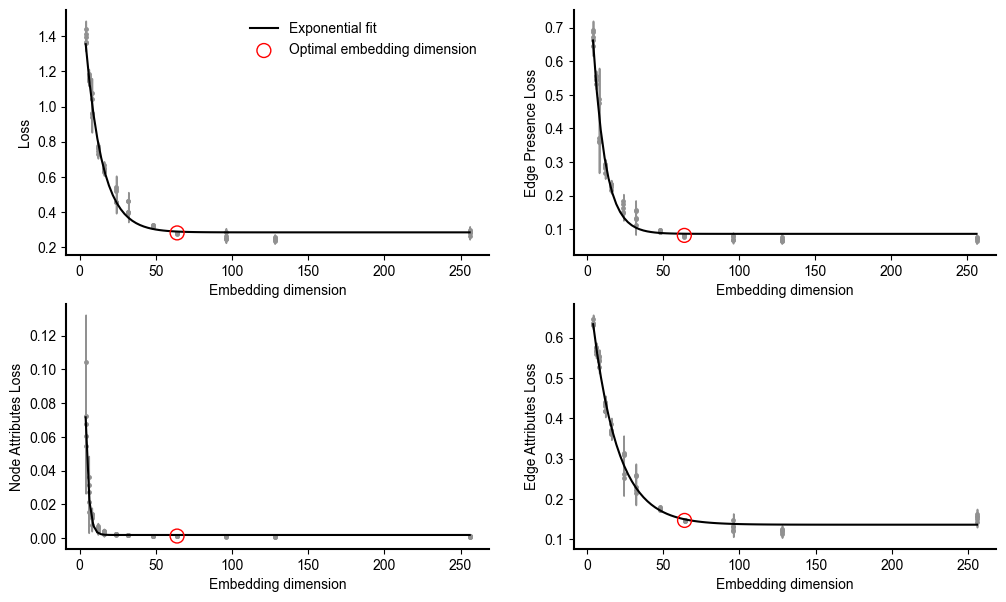

In [17]:
# Plot embedding-loss distributions with an exponential fit.
def exp_decay(x, a, lam, c):
    return a * np.exp(-lam * x) + c

fig, axs = plt.subplots(2, 2,figsize=(12, 7))
axes = axs.flatten()

values = ["abcd_loss", "abcd_edge_presence_loss", "abcd_node_attr_loss", "abcd_edge_attr_loss"]
labels = ["Loss", "Edge Presence Loss", "Node Attributes Loss", "Edge Attributes Loss"]
dims = np.sort(emb_df["embedding_dim"].unique())

for ax, val, lab in zip(axes, values, labels):
    sns.violinplot(
        data=emb_df, x="embedding_dim", y=val, ax=ax, color="0.95",
        legend=False, native_scale=True, inner="point", 
    )

    # Some formatting
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_linewidth(1.5)
    ax.set_ylabel(lab)
    ax.set_xlabel("Embedding dimension")

    # Fit on the real dimensions and draw the curve on that same scale.
    popt, _ = curve_fit(exp_decay, emb_df["embedding_dim"], emb_df[val], p0=[1, 1, 0])
    a, lam, c = popt
    x_fit = np.linspace(dims.min(), dims.max(), 100)
    y_fit = exp_decay(x_fit, a, lam, c)
    ax.plot(x_fit, y_fit, color="black", label="Exponential fit", zorder=3)
    # Tag the 64 embedding dimension as the optimal one.
    ax.scatter(64, np.median(emb_df[emb_df["embedding_dim"] == 64][val]), edgecolor="red", 
                facecolor="none", zorder=4, label="Optimal embedding dimension", s=100)

    if ax == axes[0]:
        ax.legend(frameon=False)

plt.show()


In [19]:
emb_df.head()

,embedding_dim,repetition,abcd_loss,abcd_edge_presence_loss,abcd_node_attr_loss,abcd_edge_attr_loss,abcd_kl_loss,geste_loss,geste_edge_presence_loss,geste_node_attr_loss,...,geste_node_volume_corr,geste_node_surface_corr,geste_node_thickness_corr,geste_edge_afd_fixel_corr,geste_edge_pearsoncorrelation_corr,banda_node_volume_corr,banda_node_surface_corr,banda_node_thickness_corr,banda_edge_afd_fixel_corr,banda_edge_pearsoncorrelation_corr
0,4,1,1.362376,0.644103,0.067475,0.633187,17.611917,1.555074,0.783388,0.088254,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6,1,1.163772,0.546617,0.036460,0.559356,21.339118,1.276292,0.590508,0.050521,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8,1,1.074720,0.487504,0.014113,0.544771,28.332268,1.157480,0.531496,0.019615,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,12,1,0.729846,0.266070,0.006932,0.418503,38.340639,0.769367,0.301671,0.010517,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,16,1,0.629041,0.217899,0.002234,0.366619,42.289209,0.701637,0.275637,0.002743,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


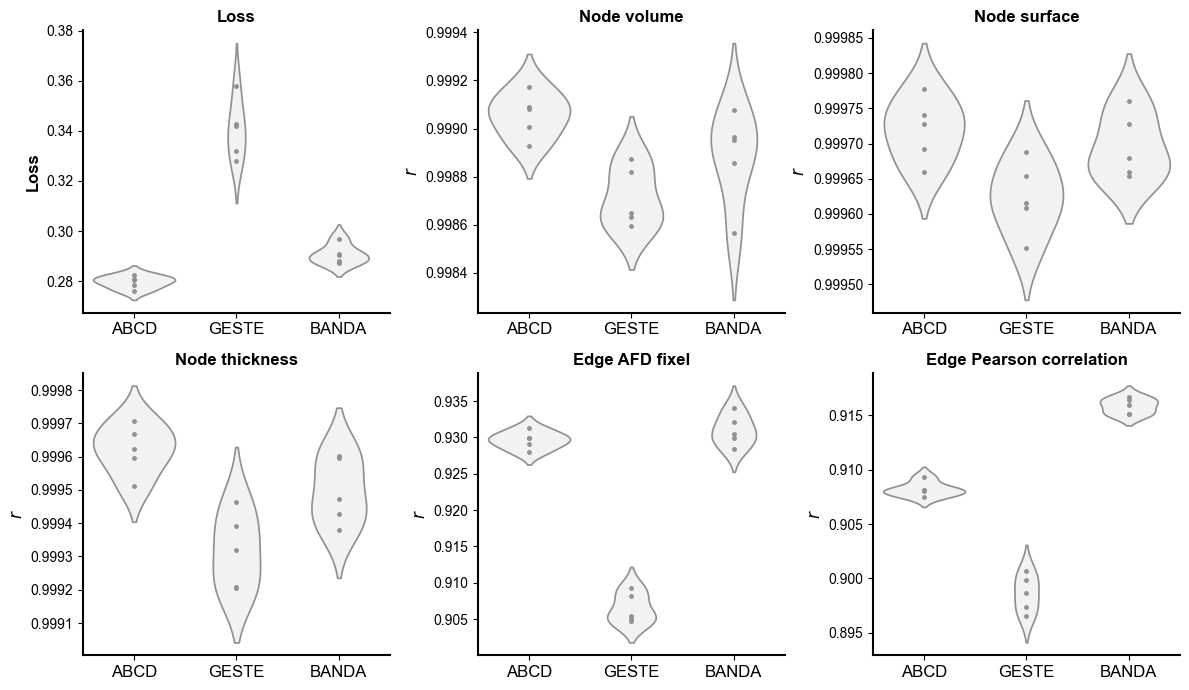

In [29]:
# Compare loss and correlations across cohorts at the optimal embedding dimension.
metrics = {
    "Loss": {
        "abcd_loss": "ABCD",
        "geste_loss": "GESTE",
        "banda_loss": "BANDA",
    },
    "Node volume": {
        "abcd_node_volume_corr": "ABCD",
        "geste_node_volume_corr": "GESTE",
        "banda_node_volume_corr": "BANDA",
    },
    "Node surface": {
        "abcd_node_surface_corr": "ABCD",
        "geste_node_surface_corr": "GESTE",
        "banda_node_surface_corr": "BANDA",
    },
    "Node thickness": {
        "abcd_node_thickness_corr": "ABCD",
        "geste_node_thickness_corr": "GESTE",
        "banda_node_thickness_corr": "BANDA",
    },
    "Edge AFD fixel": {
        "abcd_edge_afd_fixel_corr": "ABCD",
        "geste_edge_afd_fixel_corr": "GESTE",
        "banda_edge_afd_fixel_corr": "BANDA",
    },
    "Edge Pearson correlation": {
        "abcd_edge_pearsoncorrelation_corr": "ABCD",
        "geste_edge_pearsoncorrelation_corr": "GESTE",
        "banda_edge_pearsoncorrelation_corr": "BANDA",
    },
}

fig, axs = plt.subplots(2, 3, figsize=(12, 7))
for ax, (label, cols) in zip(axs.flatten(), metrics.items()):
    dim64 = emb_df.loc[emb_df["embedding_dim"] == 64, ["repetition", *cols]]
    long = dim64.melt(id_vars="repetition", var_name="cohort", value_name="value")
    long["cohort"] = long["cohort"].map(cols)

    sns.violinplot(
        data=long, x="cohort", y="value", order=["ABCD", "GESTE", "BANDA"],
        color="0.95", inner="point", ax=ax, legend=False,
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_linewidth(1.5)
    ax.set_xlabel("")
    if ax == axs[0, 0]:
        ax.set_ylabel("Loss", fontsize=12, fontweight='bold')
    else:
        ax.set_ylabel("$r$", fontsize=12, fontweight='bold')
    ax.set_title(label, fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', labelsize=12)
    # Set the y-axis ticks to max two decimal places.
    #ax.yaxis.set_major_locator(plt.MaxNLocator(2))

plt.tight_layout()
plt.show()


In [35]:
# Load up the ablation results.
ablation_df = pd.read_csv(f"{output_dir}/dimension_importance.csv")

# Append 1 to the dim column.
ablation_df["dim"] = ablation_df["dim"].astype(int) + 1
ablation_df.head()

,dim,mean_delta_total_loss,median_delta_total_loss,mean_importance_total_loss,median_importance_total_loss,mean_delta_edge_presence_loss,median_delta_edge_presence_loss,mean_importance_edge_presence_loss,median_importance_edge_presence_loss,mean_delta_node_attr_loss,...,mean_importance_edge_attr_loss,median_importance_edge_attr_loss,mean_node_variance,median_node_variance,mean_edge_abs_diff,median_edge_abs_diff,mean_greedy_rank,mean_greedy_incremental_delta_total_loss,mean_greedy_cumulative_delta_total_loss,in_loo_importance_topk
0,1,0.003494,0.003074,0.001466,0.001079,-0.014547,-0.014238,2.005957e-07,0.000000,3.076558e-05,...,0.031742,0.029848,0.892958,0.872118,1.029664,1.024080,18.137662,0.473984,8.303740,False
1,2,0.000098,0.000097,0.000036,0.000035,0.000097,0.000096,6.121281e-05,0.000061,9.668746e-09,...,0.000003,0.000003,0.000436,0.000425,0.021436,0.021167,25.992208,0.001325,9.084436,False
2,3,0.000070,0.000069,0.000025,0.000025,0.000069,0.000068,4.356997e-05,0.000043,-1.267674e-07,...,0.000002,0.000002,0.000274,0.000265,0.015564,0.015280,47.451948,0.000818,9.106402,False
3,4,0.000068,0.000068,0.000025,0.000024,0.000067,0.000067,4.288891e-05,0.000042,5.508871e-08,...,0.000002,0.000002,0.000423,0.000419,0.019530,0.019430,38.927273,0.000980,9.098171,False
4,5,0.000056,0.000055,0.000020,0.000020,0.000055,0.000054,3.477155e-05,0.000034,-2.670310e-07,...,0.000002,0.000002,0.000475,0.000471,0.019261,0.019215,25.906494,0.001346,9.083352,False


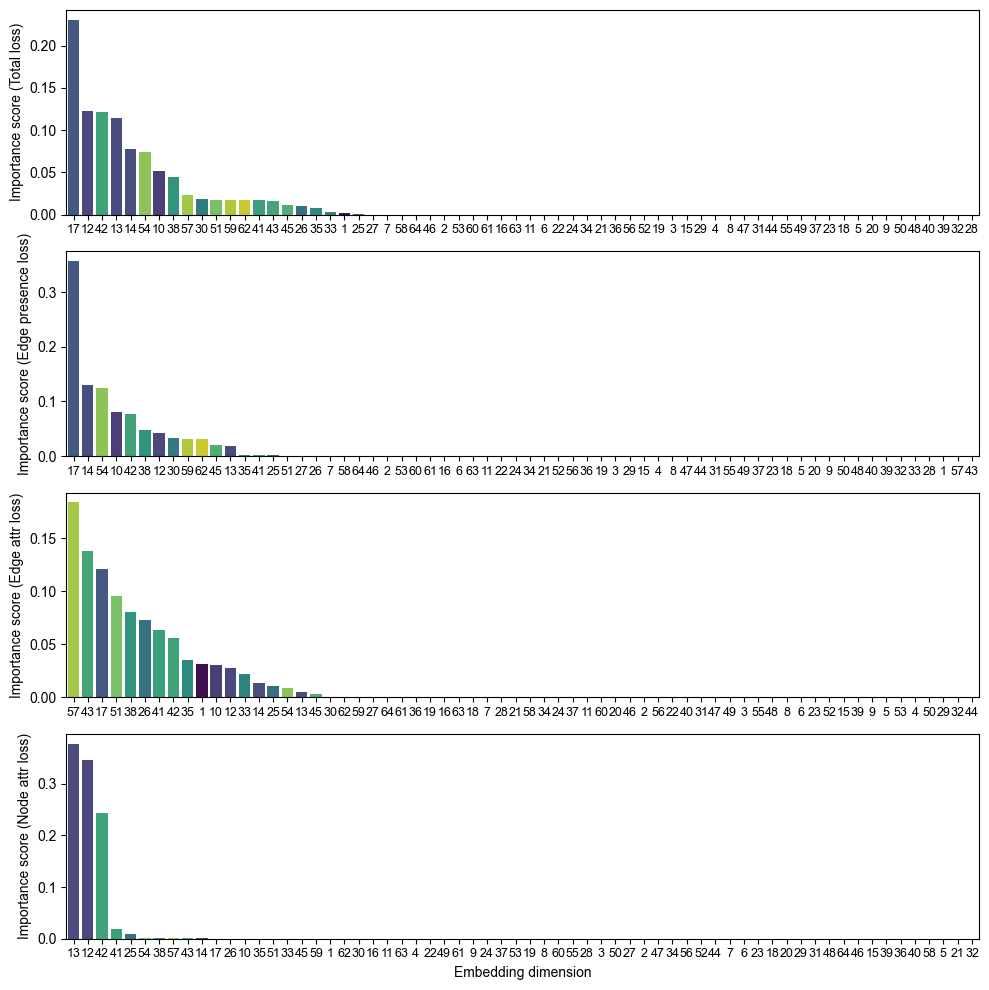

In [36]:
# Plot the importance score for each dimension as a ranked bar plot, using 4 subplots:
# mean_importance_total_loss, mean_importance_edge_presence_loss, mean_importance_edge_attr_loss, and mean_importance_node_attr_loss

fig, axes = plt.subplots(4, 1, figsize=(10, 10))

for i, loss_type in enumerate(["total_loss", "edge_presence_loss", "edge_attr_loss", "node_attr_loss"]):
    ax = axes.flatten()[i]
    sns.barplot(x="dim", y=f"mean_importance_{loss_type}", data=ablation_df, ax=ax, hue="dim",
                palette=sns.color_palette("viridis", n_colors=len(ablation_df)), legend=False,
                order=ablation_df.sort_values(f"mean_importance_{loss_type}", ascending=False)["dim"])
    ax.set_ylabel(f"Importance score ({loss_type.replace('_', ' ').capitalize()})")
    ax.tick_params(axis="x", rotation=0, labelsize=9)
    if ax == axes[-1]:
        ax.set_xlabel("Embedding dimension")
    else:
        ax.set_xlabel("")

plt.tight_layout()
plt.show()

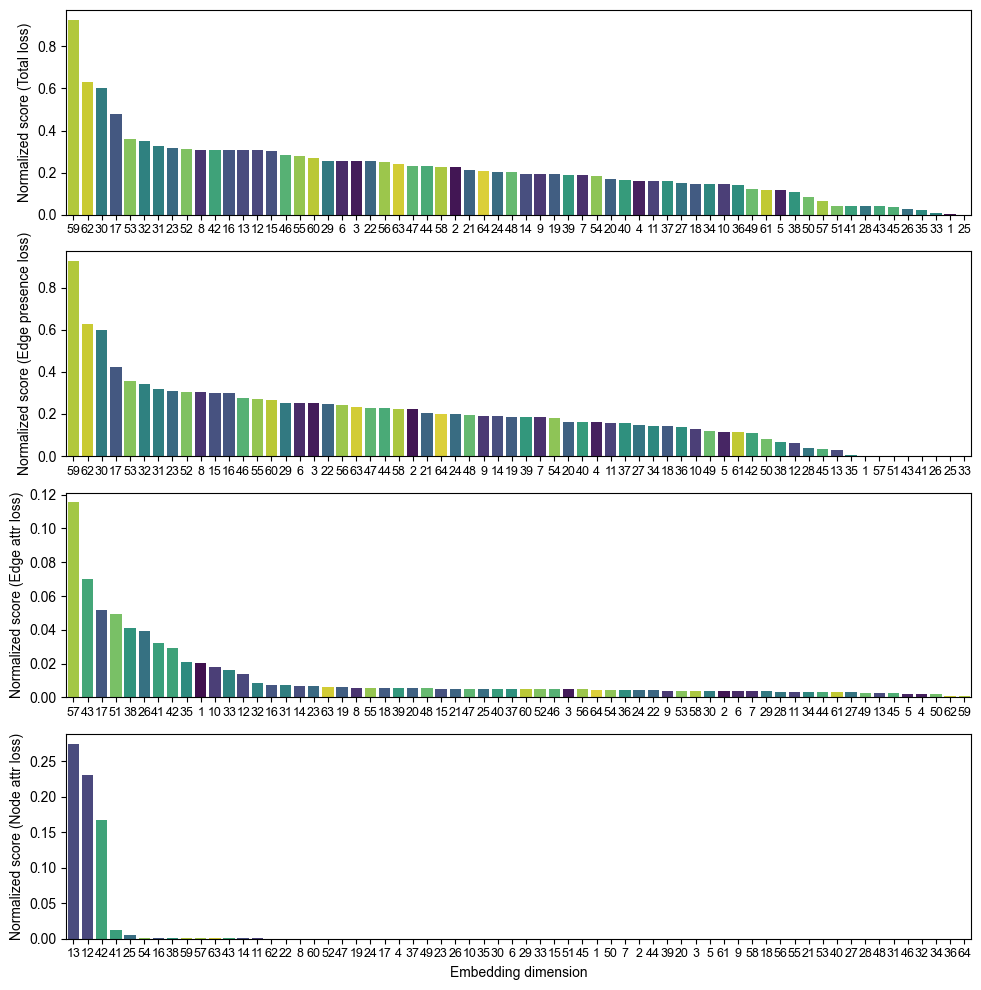

In [37]:
# Normalize the importance score for each dimension by their variance
for loss_type in ["total_loss", "edge_presence_loss", "edge_attr_loss", "node_attr_loss"]:
    ablation_df[f"normalized_importance_{loss_type}"] = ablation_df[f"mean_delta_{loss_type}"].clip(lower=0) / (ablation_df["mean_node_variance"] + 1e-6)

# Plot the normalized importance score for each dimension as a ranked bar plot, using 4 subplots:
# normalized_importance_total_loss, normalized_importance_edge_presence_loss, normalized_importance_edge_attr_loss, and normalized_importance_node_attr_loss

fig, axes = plt.subplots(4, 1, figsize=(10, 10))

for i, loss_type in enumerate(["total_loss", "edge_presence_loss", "edge_attr_loss", "node_attr_loss"]):
    ax = axes.flatten()[i]
    sns.barplot(x="dim", y=f"normalized_importance_{loss_type}", data=ablation_df, ax=ax, hue="dim",
                palette=sns.color_palette("viridis", n_colors=len(ablation_df)), legend=False,
                order=ablation_df.sort_values(f"normalized_importance_{loss_type}", ascending=False)["dim"])
    ax.set_ylabel(f"Normalized score ({loss_type.replace('_', ' ').capitalize()})")
    ax.tick_params(axis="x", rotation=0, labelsize=9)
    if ax == axes[-1]:
        ax.set_xlabel("Embedding dimension")
    else:
        ax.set_xlabel("")

plt.tight_layout()
plt.show()